# II.5 ? Comparaci?n descriptiva de combusti?n a carga semejante

Este cuaderno ejecuta el contraste fijado en `outputs/serie2_carga/diseno_previo.md`: si aire secundario relativamente alto y bajo acompa?a diferencias registradas de O2 y gases del economizador cuando vapor y presi?n son similares. Usa bloques de cinco minutos y emparejamiento dentro del d?a. No atribuye causalidad ni cuantifica eficiencia o ahorro.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd()
if not (RAIZ / 'data/raw/serie2/data.csv').exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
from scripts.comparar_carga_serie2 import cargar_crudo, agregar_bloques, ejecutar

CRUDO = RAIZ / 'data/raw/serie2/data.csv'
OUT = RAIZ / 'outputs/serie2_carga'
OUT.mkdir(parents=True, exist_ok=True)
datos = cargar_crudo(CRUDO)
bloques_crudos = agregar_bloques(datos)
print(f"Filas: {len(datos):,}; desde {datos.date.min()} hasta {datos.date.max()}")
print('Cadencia:', datos.date.diff().dropna().value_counts().head().to_dict())
print('Bloques:', len(bloques_crudos), '| cobertura insuficiente:', int((~bloques_crudos.cobertura_ok).sum()))
print('Faltantes en se?ales del contraste:')
datos[['FT_8302.AV_0#','ZZQBCHLL.AV_0#','PTCA_8324.AV_0#','AIR_8301A.AV_0#','AIR_8301B.AV_0#','TE_8319A.AV_0#','TE_8319B.AV_0#','FT_8306A.AV_0#','FT_8306B.AV_0#']].isna().sum()

Filas: 86,400; desde 2022-03-27 14:28:54 hasta 2022-04-01 14:28:49
Cadencia: {Timedelta('0 days 00:00:05'): 86399}
Bloques: 1440 | cobertura insuficiente: 0
Faltantes en se?ales del contraste:


FT_8302.AV_0#      0
ZZQBCHLL.AV_0#     0
PTCA_8324.AV_0#    0
AIR_8301A.AV_0#    0
AIR_8301B.AV_0#    0
TE_8319A.AV_0#     0
TE_8319B.AV_0#     0
FT_8306A.AV_0#     0
FT_8306B.AV_0#     0
dtype: int64

## Lectura de los datos fuente

El CSV conserva 86,400 filas a cinco segundos. Cada bloque contiene 60 lecturas esperadas. El filtro exige 55/60 por se?al; no se interpola. Las medianas describen bloques y evitan contar lecturas consecutivas como r?plicas.

In [2]:
principal = ejecutar(CRUDO, OUT, estabilidad=1.0, caliper_variable=.20,
                     caliper_total=.30, datos=datos, bloques_crudos=bloques_crudos)
print(principal['conteos'])
display(principal['por_dia'])
display(principal['bloques'].motivo.value_counts().rename_axis('motivo').to_frame('bloques'))

{'filas_crudas': 86400, 'bloques': 1440, 'filas_en_bloques_emparejados': 0, 'filas_fuera_contraste': 86400, 'pares': 0, 'estabilidad_rango_unidades_originales': 1.0, 'caliper_por_variable_sd': 0.2, 'caliper_euclideo_sd': 0.3}


,dia,bloques,elegibles,soporte,tercil_bajo,tercil_alto,pares
0,2022-03-27,115,8,0,3,3,0
1,2022-03-28,288,6,0,2,2,0
2,2022-03-29,288,17,0,6,6,0
3,2022-03-30,288,8,0,3,3,0
4,2022-03-31,288,12,0,4,4,0
5,2022-04-01,173,14,0,5,5,0


,bloques
motivo,
inestable_en_vapor_o_presion,1375
sin_pareja_dentro_de_caliper,46
tercil_medio_no_en_contraste_primario,19


## Contraste principal y matriz de sensibilidad

El criterio principal exige rango intrabloque ?1.0 en la escala original de vapor y presi?n, y diferencias de carga ?0.20 desviaciones est?ndar por variable y ?0.30 eucl?deas en conjunto. La matriz predefinida contrasta rangos 0.5/1.0/2.0 y calipers individuales 0.15/0.20/0.25, manteniendo el caliper conjunto en 0.30. Los rangos son l?mites de selecci?n descriptiva, no estabilidad certificada.

In [3]:
filas = []
resultados = {}
for rango in (.5, 1.0, 2.0):
    for caliper in (.15, .20, .25):
        if (rango, caliper) == (1.0, .20):
            r = principal
        else:
            destino = OUT / 'matriz_final' / f'rango_{rango}_caliper_{caliper}'
            r = ejecutar(CRUDO, destino, estabilidad=rango, caliper_variable=caliper,
                         caliper_total=.30, datos=datos, bloques_crudos=bloques_crudos)
        resultados[(rango, caliper)] = r
        dia = r['por_dia']
        balance = r['balance'].query("etapa == 'despues'")
        extremos = dia.tercil_bajo.sum() + dia.tercil_alto.sum()
        filas.append({
            'rango_original': rango,
            'caliper_sd_variable': caliper,
            'caliper_total_sd': .30,
            'bloques_elegibles': int(r['bloques'].elegible.sum()),
            'pares': len(r['pares']),
            'bloques_pareados': 2 * len(r['pares']),
            'fraccion_extremos_emparejados': (2 * len(r['pares']) / extremos) if extremos else 0.0,
            'filas_fuente_emparejadas': r['conteos']['filas_en_bloques_emparejados'],
            'max_abs_smd_vapor_despues': balance.loc[balance.variable == 'ZZQBCHLL.AV_0#', 'diferencia_media_estandarizada'].abs().max(),
            'max_abs_smd_presion_despues': balance.loc[balance.variable == 'PTCA_8324.AV_0#', 'diferencia_media_estandarizada'].abs().max(),
        })
matriz = pd.DataFrame(filas)
matriz.to_csv(OUT / 'matriz_sensibilidad.csv', index=False)
display(matriz)

,rango_original,caliper_sd_variable,caliper_total_sd,bloques_elegibles,pares,bloques_pareados,fraccion_extremos_emparejados,filas_fuente_emparejadas,max_abs_smd_vapor_despues,max_abs_smd_presion_despues
0,0.5,0.15,0.3,0,0,0,0.000000,0,NaN,NaN
1,0.5,0.20,0.3,0,0,0,0.000000,0,NaN,NaN
2,0.5,0.25,0.3,0,0,0,0.000000,0,NaN,NaN
3,1.0,0.15,0.3,65,0,0,0.000000,0,NaN,NaN
4,1.0,0.20,0.3,65,0,0,0.000000,0,NaN,NaN
5,1.0,0.25,0.3,65,2,4,0.086957,240,0.021898,0.213486
6,2.0,0.15,0.3,1016,36,72,0.105572,4320,0.091324,0.078489
7,2.0,0.20,0.3,1016,46,92,0.134897,5520,0.091324,0.078489
8,2.0,0.25,0.3,1016,59,118,0.173021,7080,0.091324,0.078489


## Sensibilidad predefinida con rango ?2.0 y caliper 0.20

El criterio principal no produce parejas. La sensibilidad de rango ?2.0 y caliper 0.20 es la primera alternativa predefinida que permite un contraste con varias fechas; se reporta como sensibilidad, no como resultado principal.

In [4]:
sens = resultados[(2.0, .20)]
resumen = sens['resumen'].query("dia == 'total_pares_no_independientes'")
variables = ['dif__AIR_8301A.AV_0#','dif__AIR_8301B.AV_0#','dif__TE_8319A.AV_0#','dif__TE_8319B.AV_0#']
display(resumen[resumen.medida.isin(['dif__FT_8302.AV_0#', *variables])])
display(sens['balance'].query("etapa == 'despues'"))
resumen_dos = matriz[(matriz.rango_original == 1.0) & (matriz.caliper_sd_variable == .20)
                     | (matriz.rango_original == 2.0) & (matriz.caliper_sd_variable == .20)]
resumen_dos.to_csv(OUT / 'resumen_sensibilidad.csv', index=False)
display(resumen_dos)

,dia,medida,n_pares,mediana_alto_menos_bajo,q1,q3
54,total_pares_no_independientes,dif__FT_8302.AV_0#,46,2113.955,1844.40000,2505.54500
55,total_pares_no_independientes,dif__AIR_8301A.AV_0#,46,0.285,-0.04125,0.53625
56,total_pares_no_independientes,dif__AIR_8301B.AV_0#,46,0.350,-0.05500,0.64000
57,total_pares_no_independientes,dif__TE_8319A.AV_0#,46,2.365,-0.79500,5.87000
58,total_pares_no_independientes,dif__TE_8319B.AV_0#,46,2.395,-1.15375,10.77875


,dia,etapa,variable,diferencia_media_alto_menos_bajo,diferencia_media_estandarizada
2,2022-03-27,despues,ZZQBCHLL.AV_0#,-0.061250,-0.048235
3,2022-03-27,despues,PTCA_8324.AV_0#,0.003750,0.047449
6,2022-03-28,despues,ZZQBCHLL.AV_0#,0.006111,0.003261
7,2022-03-28,despues,PTCA_8324.AV_0#,0.000000,0.000000
10,2022-03-29,despues,ZZQBCHLL.AV_0#,0.042000,0.024960
11,2022-03-29,despues,PTCA_8324.AV_0#,-0.001333,-0.016621
14,2022-03-30,despues,ZZQBCHLL.AV_0#,-0.263333,-0.091324
15,2022-03-30,despues,PTCA_8324.AV_0#,-0.006667,-0.078489
18,2022-03-31,despues,ZZQBCHLL.AV_0#,0.039545,0.015068
19,2022-03-31,despues,PTCA_8324.AV_0#,0.000909,0.016152


,rango_original,caliper_sd_variable,caliper_total_sd,bloques_elegibles,pares,bloques_pareados,fraccion_extremos_emparejados,filas_fuente_emparejadas,max_abs_smd_vapor_despues,max_abs_smd_presion_despues
4,1.0,0.2,0.3,65,0,0,0.000000,0,NaN,NaN
7,2.0,0.2,0.3,1016,46,92,0.134897,5520,0.091324,0.078489


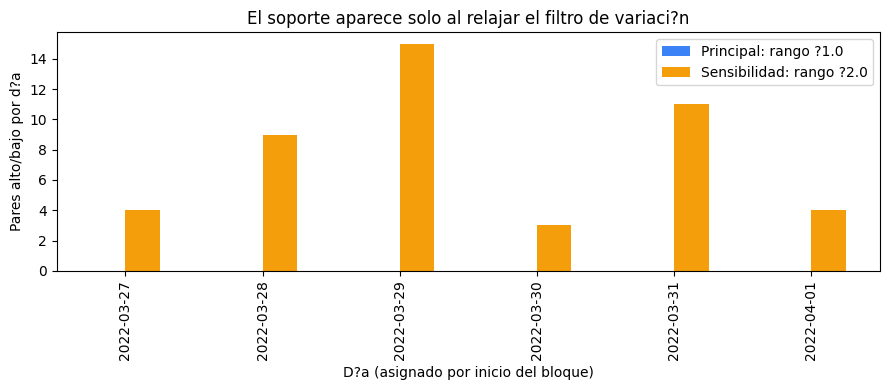

In [5]:
soporte = principal['por_dia'][['dia', 'pares']].rename(columns={'pares': 'principal_rango_1'})
soporte = soporte.merge(sens['por_dia'][['dia', 'pares']].rename(columns={'pares': 'sensibilidad_rango_2'}),
                        on='dia', how='outer').fillna(0)
ax = soporte.set_index('dia').plot(kind='bar', figsize=(9, 4), color=['#3B82F6', '#F59E0B'])
ax.set_ylabel('Pares alto/bajo por d?a')
ax.set_xlabel('D?a (asignado por inicio del bloque)')
ax.set_title('El soporte aparece solo al relajar el filtro de variaci?n')
ax.legend(['Principal: rango ?1.0', 'Sensibilidad: rango ?2.0'])
plt.tight_layout()
plt.savefig(OUT / 'soporte_por_dia.png', dpi=160)
plt.show()

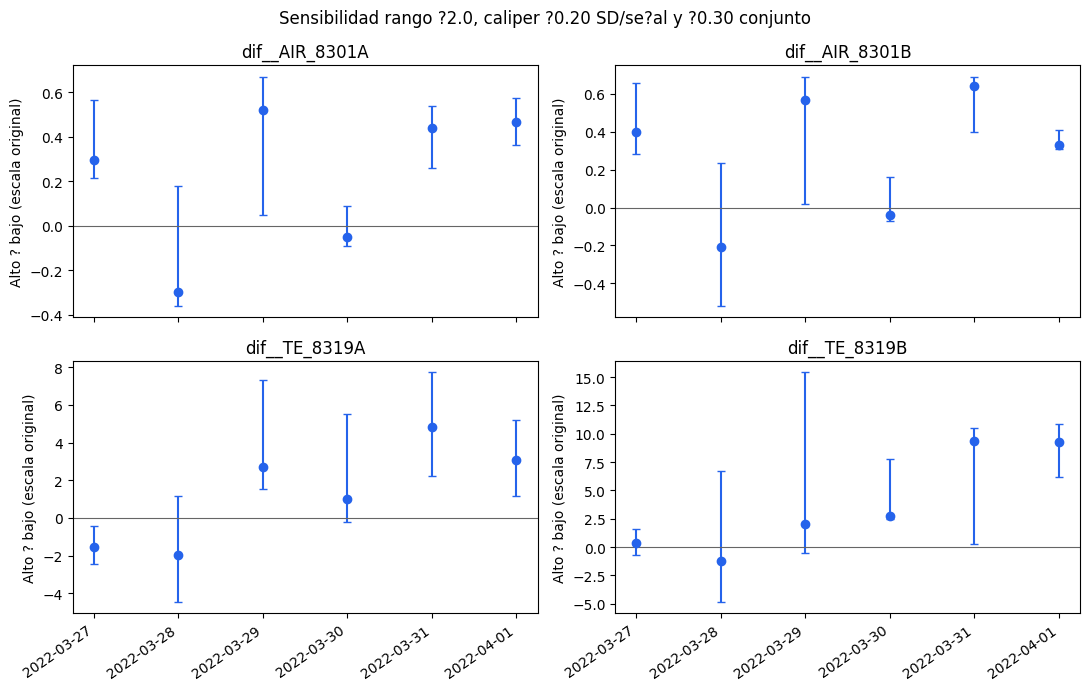

In [6]:
det = sens['detalle']
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, var in zip(axes.flat, variables):
    sub = det.groupby('dia')[var].agg(mediana='median', q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75)).reset_index()
    x = range(len(sub))
    ax.errorbar(x, sub.mediana, yerr=[sub.mediana - sub.q1, sub.q3 - sub.mediana], fmt='o', capsize=3, color='#2563EB')
    ax.axhline(0, color='#666666', linewidth=.8)
    ax.set_title(var.replace('.AV_0#', ''))
    ax.set_xticks(list(x), sub.dia, rotation=35, ha='right')
    ax.set_ylabel('Alto ? bajo (escala original)')
fig.suptitle('Sensibilidad rango ?2.0, caliper ?0.20 SD/se?al y ?0.30 conjunto')
fig.tight_layout()
fig.savefig(OUT / 'diferencias_por_dia.png', dpi=160)
plt.show()

## Interpretaci?n gerencial

Si el filtro principal no produce parejas, no existe un contraste suficientemente comparable bajo ese criterio. La sensibilidad m?s amplia muestra diferencias de O2 y gases con signos que no se repiten en todas las fechas y rangos intercuart?licos que cruzan cero; no sostiene una conclusi?n de exceso de aire, ajuste ?ptimo ni ahorro. El resultado ?til es delimitar qu? se necesita para una prueba supervisada: carga medida, unidades y calibraci?n confirmadas, combustible/poder calor?fico, CO/inquemados y temperatura de chimenea. No se modifican consignas con este an?lisis.